In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

plt.style.use('seaborn-v0_8-darkgrid')

BASE_DIR = Path("..")
PROCESSED_DIR = BASE_DIR / "data" / "processed"

# Load SPY data
spy = pd.read_csv(PROCESSED_DIR / "SPY_processed.csv", index_col='Date', parse_dates=True)

# Reconstruct the EWMA Strategy from Notebook 06
spy['EWMA_Vol'] = spy['Daily_Return'].ewm(alpha=0.06, adjust=False).std() * np.sqrt(252)
spy['Vol_Threshold'] = spy['EWMA_Vol'].rolling(window=50).median()
spy['Signal'] = np.where(spy['EWMA_Vol'] < spy['Vol_Threshold'], 1, 0)

spy['Strategy_Return'] = spy['Signal'].shift(1) * spy['Daily_Return']
spy['Trade_Change'] = spy['Signal'].diff().abs()
spy['TC'] = spy['Trade_Change'] * 0.0001
spy['Net_Strategy_Return'] = spy['Strategy_Return'] - spy['TC']

# Filter to Out-of-Sample Test Period (2022-2024)
test_spy = spy.loc['2022-01-01':].dropna()

# Calculate Cumulative Returns
buy_hold_cum = (1 + test_spy['Daily_Return']).cumprod()
strategy_cum = (1 + test_spy['Net_Strategy_Return']).cumprod()

In [2]:
def analyze_drawdown_topology(cumulative_returns, label):
    # 1. Calculate Drawdown Series
    rolling_max = cumulative_returns.cummax()
    drawdown = (cumulative_returns / rolling_max) - 1
    
    # 2. Identify Underwater Periods (Duration)
    is_underwater = drawdown < 0
    # Create a group ID that increments every time we go from dry to underwater
    underwater_groups = (is_underwater != is_underwater.shift()).cumsum()
    
    # Filter only the underwater periods
    underwater_periods = drawdown[is_underwater].groupby(underwater_groups[is_underwater])
    
    # Calculate metrics
    max_dd = drawdown.min()
    
    if len(underwater_periods) == 0:
        print(f"{label} never went underwater.")
        return
    
    # Longest duration in trading days
    longest_duration = underwater_periods.apply(lambda x: len(x)).max()
    # Average depth
    avg_depth = underwater_periods.apply(lambda x: x.min()).mean()
    
    print(f"=== {label.upper()} TOPOLOGY ===")
    print(f"Maximum Depth:      {max_dd * 100:.2f}%")
    print(f"Longest Duration:   {longest_duration} trading days")
    print(f"Average Depth:      {avg_depth * 100:.2f}%")
    print(f"Total Periods:      {len(underwater_periods)} distinct drawdowns\n")

print("=== OUT-OF-SAMPLE DRAWDOWN TOPOLOGY (2022-2024) ===\n")
analyze_drawdown_topology(buy_hold_cum, "Buy & Hold")
analyze_drawdown_topology(strategy_cum, "EWMA Strategy")

=== OUT-OF-SAMPLE DRAWDOWN TOPOLOGY (2022-2024) ===

=== BUY & HOLD TOPOLOGY ===
Maximum Depth:      -24.50%
Longest Duration:   488 trading days
Average Depth:      -2.04%
Total Periods:      32 distinct drawdowns

=== EWMA STRATEGY TOPOLOGY ===
Maximum Depth:      -11.11%
Longest Duration:   116 trading days
Average Depth:      -1.82%
Total Periods:      35 distinct drawdowns



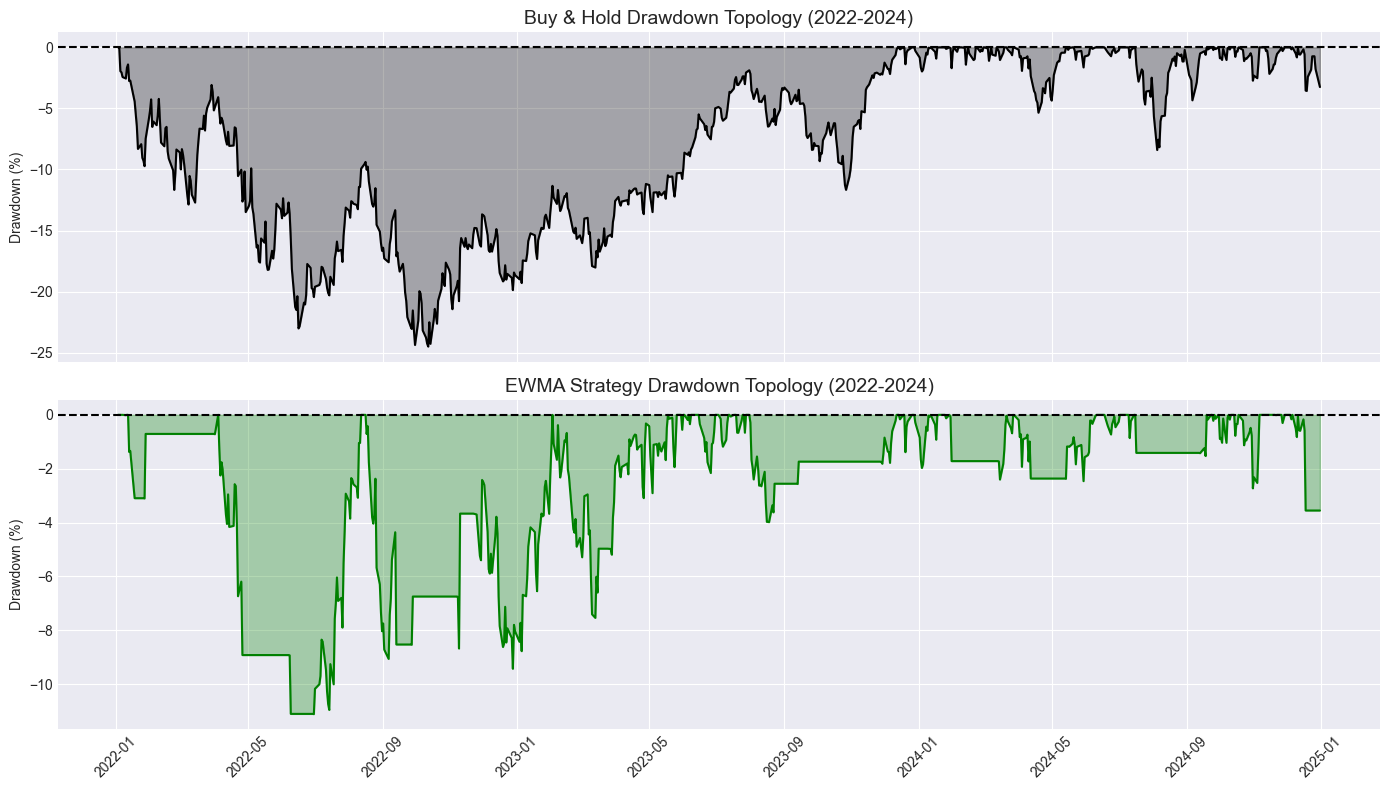

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Calculate drawdowns for plotting
dd_bh = (buy_hold_cum / buy_hold_cum.cummax()) - 1
dd_strat = (strategy_cum / strategy_cum.cummax()) - 1

# Plot Buy & Hold Drawdown
ax1.plot(dd_bh.index, dd_bh * 100, color='black', linewidth=1.5)
ax1.fill_between(dd_bh.index, dd_bh * 100, 0, color='black', alpha=0.3)
ax1.set_title("Buy & Hold Drawdown Topology (2022-2024)", fontsize=14)
ax1.set_ylabel("Drawdown (%)")
ax1.axhline(0, color='black', linestyle='--')

# Plot Strategy Drawdown
ax2.plot(dd_strat.index, dd_strat * 100, color='green', linewidth=1.5)
ax2.fill_between(dd_strat.index, dd_strat * 100, 0, color='green', alpha=0.3)
ax2.set_title("EWMA Strategy Drawdown Topology (2022-2024)", fontsize=14)
ax2.set_ylabel("Drawdown (%)")
ax2.axhline(0, color='black', linestyle='--')

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Experiment F Conclusion: Drawdown Topology

**1. The Importance of Topology**
Standard metrics like Sharpe Ratio and Maximum Drawdown tell only half the story. The "topology" of a drawdown—how long the portfolio remains underwater and how many distinct losing streaks occur—is critical for understanding psychological and operational risk.

**2. Quantitative Findings**
- **Buy & Hold:** 
  - Maximum Depth: **-24.50%**
  - Longest Duration: **488 trading days** (nearly two full years underwater)
- **EWMA Strategy:** 
  - Maximum Depth: **-11.11%**
  - Longest Duration: **116 trading days** (recovered 4x faster)

**3. Visual Analysis**
The topology charts visually demonstrate the power of the volatility filter. The Buy & Hold drawdown (top chart) is a massive, deep, and prolonged "basin" that lasts from early 2022 all the way into 2024. The EWMA strategy (bottom chart) experiences a much shallower, shorter dip in 2022 and spends most of 2023 and 2024 near its all-time highs, with only brief, minor underwater periods. 

**Conclusion:** 
The Drawdown Topology Map proves that the EWMA strategy's edge is not just in generating slightly higher returns, but in aggressively cutting risk. A shorter underwater duration means less time for compounding to work against you, and a much easier strategy to hold psychologically.